# 12 — Toronto batch SOLWEIG for multi-day thermal scenarios

## Purpose

Notebook 11 selected a compact set of hot and matched-reference summer 2025
scenarios.

This notebook runs the **same U of T SOLWEIG configuration used successfully
in Notebook 05** for every selected scenario, while keeping urban form fixed.

For each scenario it saves:

- Tmrt raster;
- UTCI raster;
- scenario metadata JSON;
- scenario-level thermal statistics;
- batch status information.

The workflow is **restart-safe**:

- completed scenarios are skipped by default;
- status is written after every scenario;
- failed scenarios do not erase successful results.

The output from this notebook will support the next step:

**scenario-specific UTCI → thermal network → heat-conditioned accessibility**

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
from datetime import datetime
import json
import shutil
import sys
import traceback

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import solweig

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

SOLWEIG_INPUT_DIR = (
    TORONTO_INTERIM
    / "solweig"
    / "UOFT_PILOT"
)

SOLWEIG_CACHE_DIR = (
    TORONTO_INTERIM
    / "solweig_cache"
    / "UOFT_PILOT"
)

SCENARIO_DIR = (
    TORONTO_OUTPUTS
    / "thermal_scenarios"
)

MANIFEST_PATH = (
    SCENARIO_DIR
    / "toronto_summer2025_solweig_scenario_manifest.csv"
)

BATCH_OUTPUT_DIR = (
    TORONTO_OUTPUTS
    / "solweig_multiday"
)

BATCH_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SOLWEIG_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Python:", sys.version)
print(
    "SOLWEIG version:",
    getattr(solweig, "__version__", "unknown"),
)
print("Project root:", PROJECT_ROOT)
print("Batch output:", BATCH_OUTPUT_DIR)

Python: 3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]
SOLWEIG version: 0.1.0b96
Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
Batch output: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig_multiday


## 2. Batch settings

The Toronto summer scenarios all use:

- local time: **15:00**
- timezone: America/Toronto
- SOLWEIG UTC offset: **−4 hours** for summer daylight saving time

By default, scenarios with existing UTCI and Tmrt rasters are skipped.

In [2]:
TORONTO_TIMEZONE = "America/Toronto"
UTC_OFFSET = -4

SKIP_COMPLETED = True
REUSE_ORIGINAL_ANCHOR = True

ORIGINAL_ANCHOR_DIR = (
    TORONTO_OUTPUTS
    / "solweig"
    / "UOFT_PILOT_2025-07-25_1500"
)

print("Skip completed:", SKIP_COMPLETED)
print("Reuse original anchor:", REUSE_ORIGINAL_ANCHOR)

Skip completed: True
Reuse original anchor: True


## 3. Load and validate scenario manifest

In [3]:
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Scenario manifest not found: {MANIFEST_PATH}. "
        "Run Notebook 11 first."
    )

manifest = pd.read_csv(
    MANIFEST_PATH
)

manifest["date"] = pd.to_datetime(
    manifest["date"]
)

manifest["pair_hot_date"] = pd.to_datetime(
    manifest["pair_hot_date"]
)

required_columns = [
    "scenario_id",
    "scenario_role",
    "date",
    "analysis_hour",
    "temp_1500_c",
    "rh_1500_pct",
    "wind_1500_ms",
    "sw_1500_wm2",
    "is_anchor",
]

missing = [
    col
    for col in required_columns
    if col not in manifest.columns
]

if missing:
    raise RuntimeError(
        f"Manifest missing columns: {missing}"
    )

print(
    "Scenarios:",
    len(manifest),
)

display(
    manifest[
        required_columns
    ]
)

Scenarios: 14


,scenario_id,scenario_role,date,analysis_hour,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2,is_anchor
0,hot_2025-06-22_1500,hot,2025-06-22,15,31.5,66,2.28,777.0,False
1,reference_2025-06-29_1500,reference,2025-06-29,15,25.0,45,3.18,891.0,False
2,hot_2025-06-23_1500,hot,2025-06-23,15,35.1,40,4.60,833.0,False
3,reference_2025-06-16_1500,reference,2025-06-16,15,24.3,53,1.76,806.0,False
4,hot_2025-06-24_1500,hot,2025-06-24,15,35.9,32,5.71,761.0,False
5,reference_2025-07-08_1500,reference,2025-07-08,15,24.8,62,3.00,547.0,False
6,hot_2025-07-06_1500,hot,2025-07-06,15,32.2,40,6.36,784.0,False
7,reference_2025-07-20_1500,reference,2025-07-20,15,26.3,52,4.57,836.0,False
8,hot_2025-07-24_1500,hot,2025-07-24,15,31.6,55,5.62,747.0,False
9,reference_2025-07-03_1500,reference,2025-07-03,15,24.4,38,5.73,907.0,False


## 4. Load U of T location

In [4]:
center_path = (
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
)

if not center_path.exists():
    raise FileNotFoundError(
        center_path
    )

campus_center = gpd.read_file(
    center_path
).to_crs(4326)

latitude = float(
    campus_center.geometry.y.iloc[0]
)

longitude = float(
    campus_center.geometry.x.iloc[0]
)

location = solweig.Location(
    latitude=latitude,
    longitude=longitude,
    utc_offset=UTC_OFFSET,
)

print("Latitude :", latitude)
print("Longitude:", longitude)
print("SOLWEIG location:", location)

Latitude : 43.66371033567467
Longitude: -79.39600762899782
SOLWEIG location: Location(latitude=43.66371033567467, longitude=-79.39600762899782, altitude=0.0, utc_offset=-4)


## 5. Validate fixed SOLWEIG surface rasters

In [5]:
dsm_path = (
    SOLWEIG_INPUT_DIR
    / "dsm.tif"
)

cdsm_path = (
    SOLWEIG_INPUT_DIR
    / "cdsm.tif"
)

dem_path = (
    SOLWEIG_INPUT_DIR
    / "dem.tif"
)

raster_paths = [
    dem_path,
    dsm_path,
    cdsm_path,
]

metadata = []
validation_rows = []

for path in raster_paths:

    if not path.exists():
        raise FileNotFoundError(
            f"Missing SOLWEIG input: {path}"
        )

    with rasterio.open(path) as src:

        array = src.read(1)

        metadata.append(
            (
                src.shape,
                src.crs,
                src.transform,
                src.bounds,
            )
        )

        validation_rows.append(
            {
                "file": path.name,
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "res_x": src.res[0],
                "res_y": src.res[1],
                "min": float(
                    np.nanmin(array)
                ),
                "mean": float(
                    np.nanmean(array)
                ),
                "max": float(
                    np.nanmax(array)
                ),
            }
        )

if not all(
    item == metadata[0]
    for item in metadata[1:]
):
    raise RuntimeError(
        "DEM, DSM, and CDSM are not aligned."
    )

display(
    pd.DataFrame(
        validation_rows
    )
)

print(
    "✓ Fixed urban-form rasters are aligned."
)

,file,crs,width,height,res_x,res_y,min,mean,max
0,dem.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.207680,119.850327
1,dsm.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.678024,216.928650
2,cdsm.tif,EPSG:32617,416,416,5.0,5.0,0.000000,0.126081,13.978206


✓ Fixed urban-form rasters are aligned.


## 6. Prepare SOLWEIG surface once

Urban form is identical for every meteorological scenario, so the expensive
surface preparation is performed only once.

In [6]:
surface = solweig.SurfaceData.prepare(
    dsm=str(dsm_path),
    cdsm=str(cdsm_path),
    dem=str(dem_path),
    working_dir=str(
        SOLWEIG_CACHE_DIR
    ),
)

print(
    "✓ SOLWEIG surface prepared once for batch."
)

solweig.models.surface: Fast-path cache invalidated (1 change):
solweig.models.surface:   - kwarg 'pixel_size' changed (5.0 → None)
solweig.models.surface: Rebuilding from source rasters…
solweig.models.surface: Preparing surface data from GeoTIFF files...
solweig.models.surface_loading:   DSM: 416×416 pixels
solweig.models.surface_loading:   Extracted pixel size from DSM: 5.00 m
solweig.models.surface_loading:   CRS validated: WGS 84 / UTM zone 17N (EPSG:32617)
solweig.models.surface_loading:   ✓ Canopy DSM (CDSM) provided
solweig.models.surface_loading:   ✓ Ground elevation (DEM) provided
solweig.models.surface_loading:   → No TDSM provided - will auto-generate from CDSM (ratio=0.25)
solweig.models.surface_loading: Checking for preprocessing data...
solweig.io: No-data value is -9999.0, replacing with NaN
solweig.io: No-data value is -9999.0, replacing with NaN
solweig.models.surface_loading:   ✓ Walls found in working_dir: /scratch/project_2010417/paper3/heat-conditioned-accessibili

## 7. Prepare output raster profile and helper functions

In [7]:
with rasterio.open(
    dsm_path
) as src:

    output_profile = (
        src.profile.copy()
    )

output_profile.update(
    dtype="float32",
    count=1,
    compress="lzw",
)


def save_raster(
    path,
    array,
):

    array = np.asarray(
        array,
        dtype=np.float32,
    )

    expected_shape = (
        output_profile["height"],
        output_profile["width"],
    )

    if array.shape != expected_shape:
        raise RuntimeError(
            f"Raster shape {array.shape} "
            f"does not match {expected_shape}."
        )

    with rasterio.open(
        path,
        "w",
        **output_profile,
    ) as dst:

        dst.write(
            array,
            1,
        )


def raster_stats(
    array,
    prefix,
):

    valid = np.asarray(
        array,
        dtype=float,
    )

    valid = valid[
        np.isfinite(valid)
    ]

    if len(valid) == 0:
        raise RuntimeError(
            f"No finite values in {prefix} raster."
        )

    return {
        f"{prefix}_min_C": float(
            np.min(valid)
        ),
        f"{prefix}_p05_C": float(
            np.percentile(
                valid,
                5,
            )
        ),
        f"{prefix}_mean_C": float(
            np.mean(valid)
        ),
        f"{prefix}_median_C": float(
            np.median(valid)
        ),
        f"{prefix}_p95_C": float(
            np.percentile(
                valid,
                95,
            )
        ),
        f"{prefix}_max_C": float(
            np.max(valid)
        ),
        f"{prefix}_sd_C": float(
            np.std(valid)
        ),
    }


def read_raster_array(
    path,
):

    with rasterio.open(
        path
    ) as src:

        return src.read(
            1
        ).astype(
            np.float32
        )

## 8. Optional reuse of the original 25 July anchor

Notebook 05 already produced the anchor Tmrt and UTCI rasters.

If present, they are copied into the common batch-output structure rather
than recalculated.

In [8]:
original_anchor_tmrt = (
    ORIGINAL_ANCHOR_DIR
    / "tmrt_2025-07-25_1500.tif"
)

original_anchor_utci = (
    ORIGINAL_ANCHOR_DIR
    / "utci_2025-07-25_1500.tif"
)

print(
    "Original anchor Tmrt exists:",
    original_anchor_tmrt.exists(),
)

print(
    "Original anchor UTCI exists:",
    original_anchor_utci.exists(),
)

Original anchor Tmrt exists: True
Original anchor UTCI exists: True


## 9. Batch-run all scenarios

Each scenario is written to:

`outputs/toronto/solweig_multiday/<scenario_id>/`

Status is saved after every iteration.

In [9]:
STATUS_PATH = (
    BATCH_OUTPUT_DIR
    / "batch_status.csv"
)

status_rows = []

for position, row in manifest.iterrows():

    scenario_id = str(
        row["scenario_id"]
    )

    scenario_role = str(
        row["scenario_role"]
    )

    scenario_date = pd.Timestamp(
        row["date"]
    )

    hour = int(
        row["analysis_hour"]
    )

    ta = float(
        row["temp_1500_c"]
    )

    rh = float(
        row["rh_1500_pct"]
    )

    ws = float(
        row["wind_1500_ms"]
    )

    global_rad = float(
        row["sw_1500_wm2"]
    )

    is_anchor = bool(
        row["is_anchor"]
    )

    scenario_output_dir = (
        BATCH_OUTPUT_DIR
        / scenario_id
    )

    scenario_output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    tmrt_path = (
        scenario_output_dir
        / f"tmrt_{scenario_date:%Y-%m-%d}_{hour:02d}00.tif"
    )

    utci_path = (
        scenario_output_dir
        / f"utci_{scenario_date:%Y-%m-%d}_{hour:02d}00.tif"
    )

    metadata_path = (
        scenario_output_dir
        / "scenario_metadata.json"
    )

    print()
    print(
        "=" * 72
    )

    print(
        f"[{position + 1}/{len(manifest)}] "
        f"{scenario_id}"
    )

    # -------------------------------------------------
    # Skip already completed scenarios
    # -------------------------------------------------

    if (
        SKIP_COMPLETED
        and tmrt_path.exists()
        and utci_path.exists()
    ):

        print(
            "Already complete — skipping simulation."
        )

        tmrt_array = read_raster_array(
            tmrt_path
        )

        utci_array = read_raster_array(
            utci_path
        )

        status = "existing"

    else:

        try:

            # -----------------------------------------
            # Reuse Notebook 05 anchor raster
            # -----------------------------------------

            if (
                REUSE_ORIGINAL_ANCHOR
                and is_anchor
                and original_anchor_tmrt.exists()
                and original_anchor_utci.exists()
            ):

                shutil.copy2(
                    original_anchor_tmrt,
                    tmrt_path,
                )

                shutil.copy2(
                    original_anchor_utci,
                    utci_path,
                )

                tmrt_array = read_raster_array(
                    tmrt_path
                )

                utci_array = read_raster_array(
                    utci_path
                )

                status = (
                    "reused_original_anchor"
                )

                print(
                    "Reused original Notebook 05 anchor."
                )

            else:

                # -------------------------------------
                # Validate meteorology
                # -------------------------------------

                values = {
                    "ta": ta,
                    "rh": rh,
                    "ws": ws,
                    "global_rad": global_rad,
                }

                for key, value in values.items():

                    if not np.isfinite(
                        value
                    ):
                        raise RuntimeError(
                            f"Non-finite {key}: {value}"
                        )

                if not (
                    -40 <= ta <= 50
                ):
                    raise RuntimeError(
                        f"Unexpected Ta: {ta}"
                    )

                if not (
                    0 <= rh <= 100
                ):
                    raise RuntimeError(
                        f"Unexpected RH: {rh}"
                    )

                if ws < 0:
                    raise RuntimeError(
                        f"Unexpected wind: {ws}"
                    )

                if global_rad < 0:
                    raise RuntimeError(
                        f"Unexpected radiation: {global_rad}"
                    )

                # -------------------------------------
                # Build scenario weather
                # -------------------------------------

                weather = solweig.Weather(
                    datetime=datetime(
                        scenario_date.year,
                        scenario_date.month,
                        scenario_date.day,
                        hour,
                        0,
                    ),
                    ta=ta,
                    rh=rh,
                    global_rad=global_rad,
                    ws=ws,
                )

                run_dir = (
                    scenario_output_dir
                    / "run"
                )

                run_dir.mkdir(
                    parents=True,
                    exist_ok=True,
                )

                # -------------------------------------
                # SOLWEIG calculation
                # -------------------------------------

                summary = solweig.calculate(
                    surface=surface,
                    weather=[
                        weather
                    ],
                    location=location,
                    output_dir=str(
                        run_dir
                    ),
                    outputs=[
                        "tmrt",
                        "shadow",
                    ],
                )

                tmrt_array = np.asarray(
                    summary.tmrt_mean,
                    dtype=np.float32,
                )

                utci_array = np.asarray(
                    summary.utci_mean,
                    dtype=np.float32,
                )

                save_raster(
                    tmrt_path,
                    tmrt_array,
                )

                save_raster(
                    utci_path,
                    utci_array,
                )

                status = "calculated"

                print(
                    "✓ SOLWEIG calculation complete."
                )

            # -----------------------------------------
            # Save scenario metadata
            # -----------------------------------------

            scenario_metadata = {
                "scenario_id": scenario_id,
                "scenario_role": scenario_role,
                "date": scenario_date.strftime(
                    "%Y-%m-%d"
                ),
                "local_hour": hour,
                "timezone": TORONTO_TIMEZONE,
                "utc_offset_used_by_solweig": UTC_OFFSET,
                "is_anchor": is_anchor,
                "latitude": latitude,
                "longitude": longitude,
                "air_temperature_C": ta,
                "relative_humidity_pct": rh,
                "wind_speed_ms": ws,
                "global_shortwave_radiation_Wm2": global_rad,
                "weather_source": (
                    "Open-Meteo historical archive "
                    "at U of T coordinates"
                ),
                "weather_interpretation": (
                    "historical gridded reconstruction; "
                    "not a single-station observation"
                ),
                "tmrt_raster": str(
                    tmrt_path
                ),
                "utci_raster": str(
                    utci_path
                ),
                "batch_status": status,
            }

            with open(
                metadata_path,
                "w",
                encoding="utf-8",
            ) as handle:

                json.dump(
                    scenario_metadata,
                    handle,
                    indent=2,
                )

        except Exception as exc:

            status_rows.append(
                {
                    "scenario_id": scenario_id,
                    "scenario_role": scenario_role,
                    "date": scenario_date,
                    "status": "failed",
                    "error": str(exc),
                }
            )

            pd.DataFrame(
                status_rows
            ).to_csv(
                STATUS_PATH,
                index=False,
            )

            print(
                "FAILED:",
                exc,
            )

            traceback.print_exc()

            continue

    # -------------------------------------------------
    # Thermal statistics
    # -------------------------------------------------

    stats = {
        "scenario_id": scenario_id,
        "scenario_role": scenario_role,
        "date": scenario_date,
        "analysis_hour": hour,
        "is_anchor": is_anchor,
        "ta_C": ta,
        "rh_pct": rh,
        "wind_ms": ws,
        "shortwave_Wm2": global_rad,
        "status": status,
        "tmrt_raster": str(
            tmrt_path
        ),
        "utci_raster": str(
            utci_path
        ),
    }

    stats.update(
        raster_stats(
            tmrt_array,
            "tmrt",
        )
    )

    stats.update(
        raster_stats(
            utci_array,
            "utci",
        )
    )

    valid_utci = (
        utci_array[
            np.isfinite(
                utci_array
            )
        ]
    )

    for threshold in [
        26,
        32,
        38,
    ]:

        stats[
            f"share_utci_above_{threshold}C"
        ] = float(
            np.mean(
                valid_utci
                > threshold
            )
        )

    status_rows.append(
        stats
    )

    pd.DataFrame(
        status_rows
    ).to_csv(
        STATUS_PATH,
        index=False,
    )

    print(
        "UTCI mean:",
        round(
            stats[
                "utci_mean_C"
            ],
            2,
        ),
        "°C",
    )

    print(
        "UTCI SD:",
        round(
            stats[
                "utci_sd_C"
            ],
            2,
        ),
        "°C",
    )

print()
print(
    "Batch loop finished."
)

print(
    "Status file:",
    STATUS_PATH,
)


[1/14] hot_2025-06-22_1500
solweig.tiling: Resource-aware tile sizing (context=solweig): GPU budget=2,147,483,647 bytes, RAM=677,601,136,640 available of 810,364,264,448 total, max_tile_side=2184 px
solweig.timeseries: ============================================================
solweig.timeseries: Starting SOLWEIG timeseries calculation
solweig.timeseries:   Grid size: 416x416 pixels
solweig.timeseries:   Timesteps: 1
solweig.timeseries:   Period: 2025-06-22 15:00 -> 2025-06-22 15:00
solweig.timeseries:   Location: 43.66N, -79.40E
solweig.timeseries: ============================================================
solweig.timeseries: Pre-computing sun positions and radiation splits...
solweig.timeseries:   Pre-computed 1 timesteps in 0.0s


error: XDG_RUNTIME_DIR is invalid or not set in the environment.
[GPU] Shadow GPU context initialized successfully
SOLWEIG timeseries:   0%|          | 0/1 [00:00<?, ?it/s]

solweig.timeseries:   SOLWEIG timeseries: pre-computing ground view factor (reused across 1 timestep)


[GPU] GVF GPU context initialized
[GPU] Anisotropic sky GPU context initialized
SOLWEIG timeseries: 100%|██████████| 1/1 [00:00<00:00,  3.07it/s]

solweig.timeseries: ============================================================
solweig.timeseries: Calculation complete: 1 timesteps processed
solweig.timeseries:   Total time: 0.3s (2.95 steps/s)
solweig.timeseries: ============================================================


...

SOLWEIG timeseries:   0%|          | 0/1 [00:00<?, ?it/s]

solweig.timeseries:   SOLWEIG timeseries: pre-computing ground view factor (reused across 1 timestep)


SOLWEIG timeseries: 100%|██████████| 1/1 [00:00<00:00,  5.37it/s]

solweig.timeseries: ============================================================
solweig.timeseries: Calculation complete: 1 timesteps processed
solweig.timeseries:   Total time: 0.2s (5.34 steps/s)
solweig.timeseries: ============================================================


rasterio._env: CPLE_IllegalArg in tmrt_2025-08-17_1500.tif: BLOCKXSIZE can only be used with TILED=YES
rasterio._env: CPLE_IllegalArg in utci_2025-08-17_1500.tif: BLOCKXSIZE can only be used with TILED=YES
✓ SOLWEIG calculation complete.
UTCI mean: 28.24 °C
UTCI SD: 0.97 °C

Batch loop finished.
Status file: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig_multiday/batch_status.csv


## 10. Load completed batch summary

Failed scenarios remain visible in the status file but are excluded from
thermal comparisons.

In [10]:
batch_status = pd.read_csv(
    STATUS_PATH
)

batch_status["date"] = pd.to_datetime(
    batch_status["date"]
)

successful = batch_status[
    batch_status[
        "status"
    ].isin(
        [
            "calculated",
            "existing",
            "reused_original_anchor",
        ]
    )
].copy()

print(
    "Successful scenarios:",
    len(successful),
    "/",
    len(manifest),
)

display(
    successful[
        [
            "scenario_id",
            "scenario_role",
            "date",
            "ta_C",
            "utci_mean_C",
            "utci_sd_C",
            "utci_min_C",
            "utci_max_C",
            "share_utci_above_32C",
            "status",
        ]
    ]
    .sort_values(
        "utci_mean_C",
        ascending=False,
    )
)

Successful scenarios: 14 / 14


,scenario_id,scenario_role,date,ta_C,utci_mean_C,utci_sd_C,utci_min_C,utci_max_C,share_utci_above_32C,status
2,hot_2025-06-23_1500,hot,2025-06-23,35.1,40.269053,0.808720,33.785564,41.378307,1.000000,calculated
4,hot_2025-06-24_1500,hot,2025-06-24,35.9,40.060696,0.694387,34.261593,41.065266,1.000000,calculated
0,hot_2025-06-22_1500,hot,2025-06-22,31.5,39.828317,0.777443,32.982830,40.804413,1.000000,calculated
12,hot_2025-07-27_1500,hot,2025-07-27,32.2,37.511650,0.897974,30.652611,38.650181,0.989922,calculated
8,hot_2025-07-24_1500,hot,2025-07-24,31.6,35.902168,0.747547,29.758356,36.806797,0.975933,calculated
10,hot_2025-07-25_1500,hot,2025-07-25,29.0,35.703808,0.636778,29.449005,36.364174,0.990962,reused_original_anchor
6,hot_2025-07-06_1500,hot,2025-07-06,32.2,35.534658,0.758878,29.318655,36.551331,0.976765,calculated
11,reference_2025-08-15_1500,reference,2025-08-15,26.4,33.548015,1.363813,25.208641,34.943687,0.964370,calculated
3,reference_2025-06-16_1500,reference,2025-06-16,24.3,31.976326,0.977571,23.514206,33.198494,0.777407,calculated
1,reference_2025-06-29_1500,reference,2025-06-29,25.0,30.575868,1.109486,21.956799,31.975105,0.000000,calculated


## 11. Compare hot and reference scenarios

In [11]:
scenario_compare = (
    successful
    .groupby(
        "scenario_role"
    )
    .agg(
        scenarios=(
            "scenario_id",
            "count",
        ),
        mean_air_temp_C=(
            "ta_C",
            "mean",
        ),
        mean_utci_C=(
            "utci_mean_C",
            "mean",
        ),
        mean_utci_sd_C=(
            "utci_sd_C",
            "mean",
        ),
        mean_share_above_32C=(
            "share_utci_above_32C",
            "mean",
        ),
    )
    .reset_index()
)

display(
    scenario_compare
)

,scenario_role,scenarios,mean_air_temp_C,mean_utci_C,mean_utci_sd_C,mean_share_above_32C
0,hot,7,32.500000,37.830050,0.760247,0.990512
1,reference,7,25.171429,30.124248,1.028445,0.248825


## 12. Plot mean UTCI across scenarios

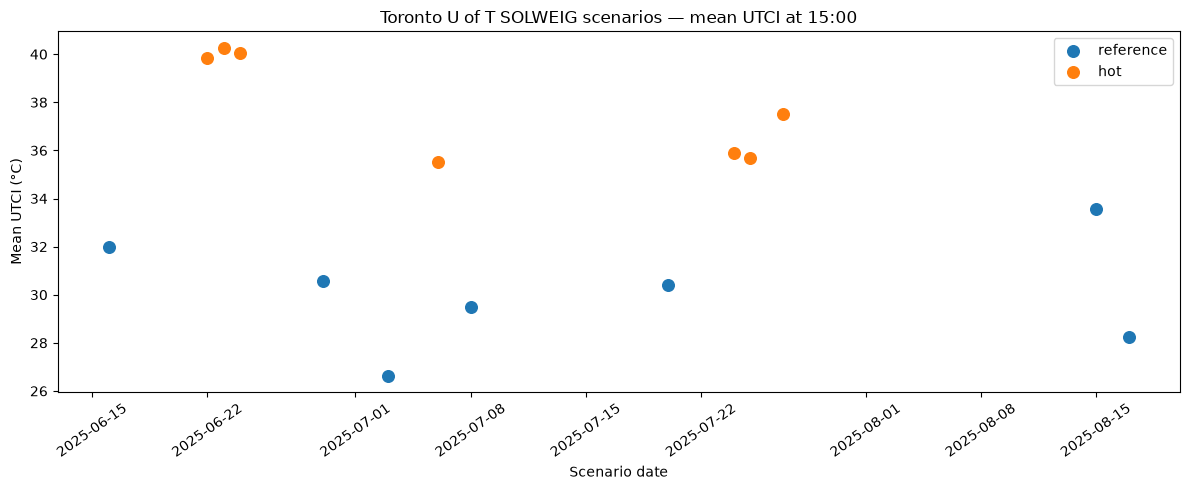

In [12]:
plot_df = (
    successful
    .sort_values(
        [
            "scenario_role",
            "date",
        ]
    )
    .copy()
)

fig, ax = plt.subplots(
    figsize=(12, 5)
)

for role in [
    "reference",
    "hot",
]:

    subset = plot_df[
        plot_df[
            "scenario_role"
        ] == role
    ]

    ax.scatter(
        subset["date"],
        subset["utci_mean_C"],
        s=70,
        label=role,
    )

ax.set_xlabel(
    "Scenario date"
)

ax.set_ylabel(
    "Mean UTCI (°C)"
)

ax.set_title(
    "Toronto U of T SOLWEIG scenarios — mean UTCI at 15:00"
)

ax.legend()

plt.xticks(
    rotation=35
)

plt.tight_layout()
plt.show()

## 13. Plot thermal spatial variability across scenarios

This diagnostic is important because Paper 4 depends not only on hotter
average conditions, but also on **spatial differentiation** in thermal
impedance.

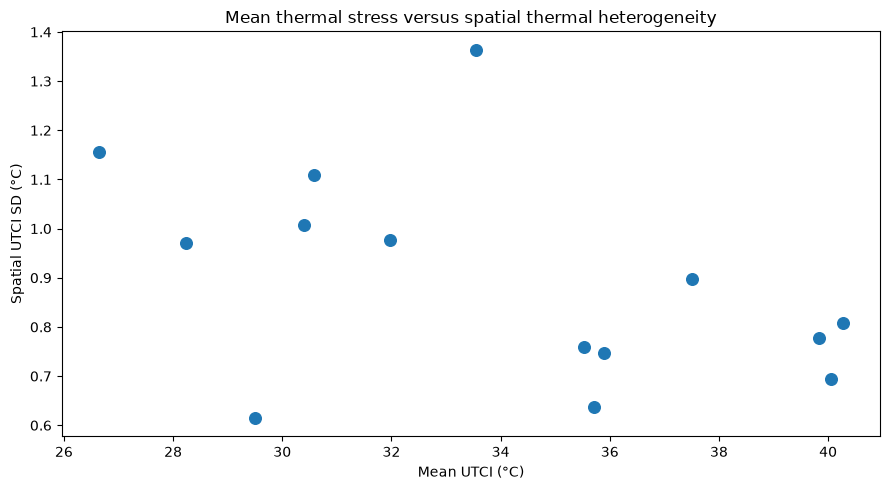

In [13]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.scatter(
    successful[
        "utci_mean_C"
    ],
    successful[
        "utci_sd_C"
    ],
    s=70,
)

ax.set_xlabel(
    "Mean UTCI (°C)"
)

ax.set_ylabel(
    "Spatial UTCI SD (°C)"
)

ax.set_title(
    "Mean thermal stress versus spatial thermal heterogeneity"
)

plt.tight_layout()
plt.show()

## 14. Save clean scenario statistics

In [14]:
SUMMARY_PATH = (
    BATCH_OUTPUT_DIR
    / "toronto_multiday_solweig_summary.csv"
)

successful.to_csv(
    SUMMARY_PATH,
    index=False,
)

print(
    "Saved:",
    SUMMARY_PATH,
)

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig_multiday/toronto_multiday_solweig_summary.csv


## 15. Final diagnostics

In [15]:
print(
    "Requested scenarios:",
    len(
        manifest
    ),
)

print(
    "Successful scenarios:",
    len(
        successful
    ),
)

print(
    "Failed scenarios:",
    int(
        (
            batch_status[
                "status"
            ] == "failed"
        ).sum()
    ),
)

print()

if len(successful) > 0:

    print(
        "Mean scenario UTCI range:",
        round(
            successful[
                "utci_mean_C"
            ].min(),
            2,
        ),
        "to",
        round(
            successful[
                "utci_mean_C"
            ].max(),
            2,
        ),
        "°C",
    )

    print(
        "Spatial UTCI SD range:",
        round(
            successful[
                "utci_sd_C"
            ].min(),
            2,
        ),
        "to",
        round(
            successful[
                "utci_sd_C"
            ].max(),
            2,
        ),
        "°C",
    )

    print(
        "Mean hot-scenario UTCI:",
        round(
            successful.loc[
                successful[
                    "scenario_role"
                ] == "hot",
                "utci_mean_C",
            ].mean(),
            2,
        ),
        "°C",
    )

    print(
        "Mean reference-scenario UTCI:",
        round(
            successful.loc[
                successful[
                    "scenario_role"
                ] == "reference",
                "utci_mean_C",
            ].mean(),
            2,
        ),
        "°C",
    )

Requested scenarios: 14
Successful scenarios: 14
Failed scenarios: 0

Mean scenario UTCI range: 26.64 to 40.27 °C
Spatial UTCI SD range: 0.61 to 1.36 °C
Mean hot-scenario UTCI: 37.83 °C
Mean reference-scenario UTCI: 30.12 °C


## Next step — Notebook 13

Notebook 13 should convert every scenario-specific UTCI raster into a
scenario-specific thermal walking network.

The key methodological question becomes:

> Does the spatial pattern and magnitude of thermal impedance change
> meaningfully across hot and reference scenarios?

It should therefore:

1. load each UTCI raster;
2. sample UTCI along the same walking edges;
3. calculate thermal cost for the same λ values;
4. preserve one identical network topology across scenarios;
5. save scenario-specific edge costs;
6. summarize how much edge-level thermal impedance changes between scenarios.

Only after that should accessibility be recomputed for every scenario.